# Inferring cortical pathways with HNN: NPE and NLE

EEG and MEG resolve neural activity in milliseconds, but a measured waveform alone does not reveal the unlderying cellular and circuit mechanisms. The **Human Neocortical Neurosolver (HNN)** bridges these scales with a biophysical cortical-column model. Because its forward map is not easily amenable to standard statistical inference, it is a natural target for simulation-based inference (SBI).

This notebook builds one seven-parameter HNN model and solves it in two ways:

1. **Neural posterior estimation (NPE)** learns the posterior directly.
2. **Neural likelihood estimation (NLE)** learns a likelihood and combines it with the same priors in PyMC.

We compare both posteriors and their HNN-based predictive fits on held-out simulations, then repeat the comparison on a recorded tactile-MEG waveform.

The formulation follows HNN's canonical three-drive event-related-potential (ERP) model. The [HNN batch-simulation tutorial](https://jonescompneurolab.github.io/textbook/content/08_using_hnn_api/batch_simulation.html), [ERP tutorial](https://jonescompneurolab.github.io/hnn-core/stable/auto_examples/workflows/plot_simulate_evoked.html), and [evoked-drive guide](https://jonescompneurolab.github.io/textbook/content/05_erps/erp_adjust_evoked_drives.html) provide the scientific and API background.


## 1. Modeling cortical dipoles

HNN represents a cortical column containing excitatory pyramidal cells and inhibitory basket cells in layers 2/3 and 5 of the neocortex. Synaptic currents flowing along aligned pyramidal dendrites form a net current dipole in nAm, directly comparable in principle with source-localized MEG or EEG.

The canonical tactile ERP is generated by an ordered sequence of external drives:

| Drive | Biological interpretation | Synaptic location | Main waveform role |
|---|---|---|---|
| Early proximal | Fast feedforward / lemniscal thalamic input | Basal and oblique dendrites, near the soma | Initiates the early positive response |
| Distal | Feedback from higher cortex or non-lemniscal thalamus | Apical dendrites | Shapes the middle negative response |
| Late proximal | Re-entrant feedforward input | Proximal dendrites | Produces the later positive response |

Each drive retains HNN's published receptor- and cell-type-specific weight profile. We infer its arrival time and a pathway-wide strength multiplier. A seventh parameter, the dipole amplitude scale $a$, captures uncertainty in effective synchronized source extent, inverse-solution calibration, and the use of a small 3×3 simulation mesh.

For circuit parameters $\theta$, random input-event times $\xi$, and measurement noise $\epsilon_j$,

$$
x(t_j)=a\,\operatorname{HNN}(t_j;\theta,\xi)+\epsilon_j,
\qquad
\epsilon_j\sim\mathcal N(0,0.5^2\ {\rm nAm}^2).
$$

We simulate waveforms up to 190 ms, smooth the aggregate dipole for 20 ms, apply HNN's standard scale factor of 3000, multiply by $a$, center each trace by its 10–20 ms mean, and retain one sample every 2 ms from 10 to 168 ms.

## 2. Parameters and priors

The timing variables are expressed as one arrival time and two positive gaps. This guarantees the biologically intended order:

$$
t_{\rm feedback}=t_{\rm early}+\Delta_{\rm feedback},
\qquad
t_{\rm late}=t_{\rm feedback}+\Delta_{\rm late}.
$$

Every prior below has support $(0,\infty)$. The quoted 90% ranges describe prior mass; they are **not** truncation limits.

| Parameter | Plain-language meaning | Positive-support prior | Central 90% | Expected influence |
|---|---|---|---|---|
| Early feedforward time | When the first sensory volley reaches proximal dendrites | LogNormal(median 26.61 ms, log-SD 0.17) | 20.1–35.2 ms | Shifts the earliest response |
| Feedback delay | Time from early input to distal feedback | LogNormal(median 36.92 ms, log-SD 0.25) | 24.5–55.7 ms | Separates early and middle components |
| Late feedforward delay | Time from feedback to re-entrant proximal input | LogNormal(median 73.59 ms, log-SD 0.17) | 55.6–97.3 ms | Separates middle and late components |
| Early feedforward gain | Multiplier of the complete early-drive conductance profile | LogNormal(median 1, log-SD 0.70) | 0.316–3.16 | Changes early pathway recruitment |
| Feedback gain | Multiplier of all distal AMPA and NMDA conductances | LogNormal(median 1, log-SD 0.70) | 0.316–3.16 | Changes the middle and slower NMDA components |
| Late feedforward gain | Multiplier of the complete late-drive conductance profile | LogNormal(median 1, log-SD 0.70) | 0.316–3.16 | Changes the late response |
| Dipole amplitude scale | Relative source-amplitude calibration after HNN's standard scaling | Gamma(shape 2, rate 0.5) | 0.71–9.49 | Matches effective source extent without distorting circuit dynamics |

The pathway gains are dimensionless; HNN's underlying conductances remain in µS. The amplitude scale is also dimensionless, with 1 meaning no correction to HNN's standard scaling. Its broader prior is needed because increasing synaptic conductance does not scale the recurrent circuit linearly. We fix HNN's temporal spreads, cell-specific synaptic delays, local connectivity, and morphology. The 0.5 nAm measurement-noise scale is a separate tutorial assumption, and can be freed as an exercise.

Positive support preserves the biological ordering and sign constraints without creating artificial upper walls for MCMC.


## 3. Simulation data

From the repository root, install the tutorial dependencies with:

    uv sync --extra dev --extra hnn

Run the HNN workflow on Linux or macOS; on Windows, use WSL as recommended by HNN-core.

To keep the notebook focused on the data and inference, the HNN model details, canonical receptor weights, positive-support prior sampler, simulation functions, and cache handling are delegated to a helper module in `misc/hnn/helpers.py`. The checked-in cache contains 4,096 training simulations. You can create new simulations by setting `REGENERATE = True`.


In [1]:
from math import log

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import seaborn as sns

from sklearn.decomposition import PCA

import bayesflow as bf
from bayesflow.wrappers.pymc import NeuralDistribution

from misc.hnn import helpers as hnn

INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


INFO:bayesflow:Using backend 'jax'


/home/radevs/Desktop/Projects/bayesflow/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
N_JOBS = 4
N_PCA_COMPONENTS = 20
NPE_DROPOUT = 0.3
NLE_DROPOUT = 0.5
N_POSTERIOR_PREDICTIVE = 64

METHOD_COLORS = {"NPE": "#2A9D8F", "NLE": "#E76F51"}
PRIOR_COLOR = "#8A8A8A"
OBSERVED_COLOR = "#161616"
PCA_COLOR = "#6F4E7C"

TIME_GRID = hnn.TIME_GRID
PARAMETER_NAMES = hnn.PARAMETER_NAMES
PARAMETER_LABELS = hnn.PARAMETER_LABELS
PRIOR_SPECS = hnn.PRIOR_SPECS

sns.set_theme(style="white", context="notebook")

In [3]:
REGENERATE = False
train, validation, test, cache_metadata = hnn.load_dataset(regenerate=REGENERATE, n_jobs=N_JOBS)

### Prior-predictive waveforms

The same simulated waveforms are colored by each inferred parameter. Timing variables move response components, pathway gains alter shape through recurrent excitation and inhibition, and the amplitude scale changes the observation magnitude without changing circuit dynamics. Every panel marginalizes over the other six parameters and stochastic input events.


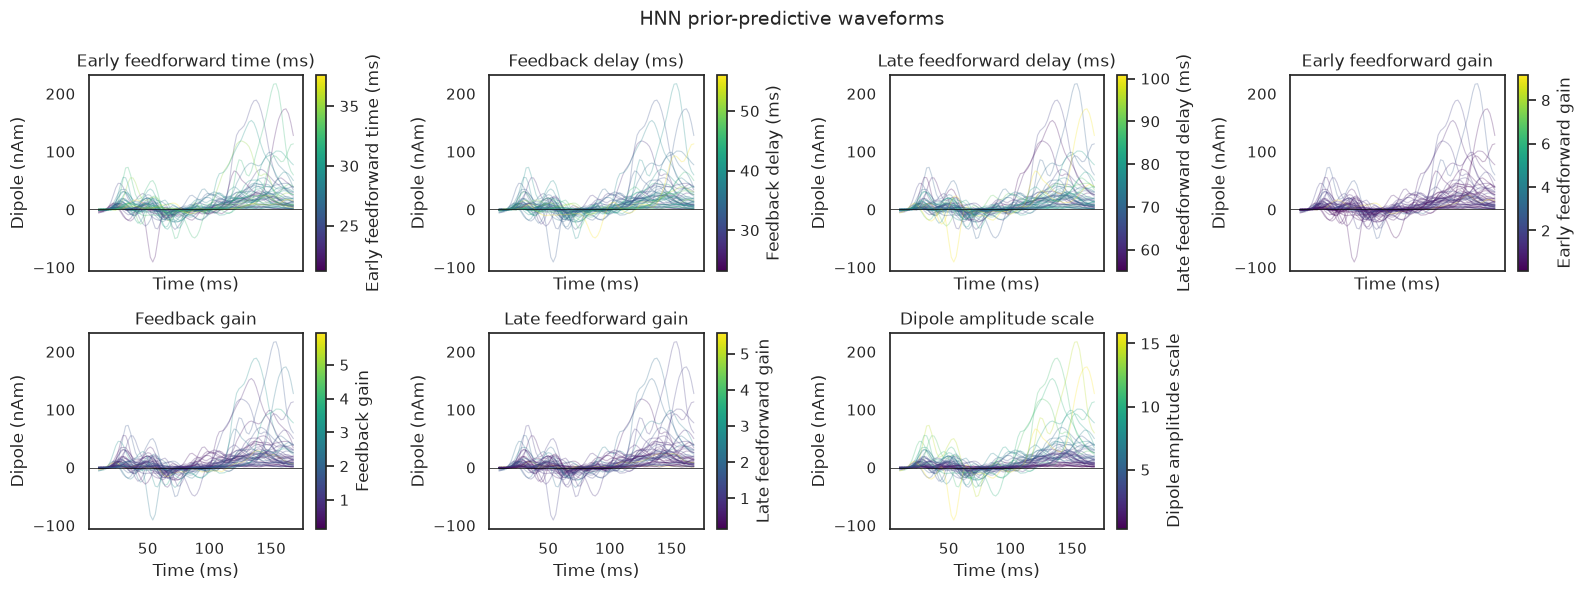

In [4]:
n_show = 50
show_indices = np.linspace(0, len(train["dipole"]) - 1, n_show, dtype=int)
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)

for axis, name, label in zip(axes.flat, PARAMETER_NAMES, PARAMETER_LABELS):
    values = train[name][show_indices, 0]
    normalization = plt.Normalize(values.min(), values.max())
    colors = plt.cm.viridis(normalization(values))

    for waveform, color in zip(train["dipole"][show_indices], colors):
        axis.plot(TIME_GRID, waveform, color=color, alpha=0.28, linewidth=0.8)

    colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=normalization, cmap="viridis"), ax=axis)
    colorbar.set_label(label)
    axis.axhline(0.0, color="black", linewidth=0.5)
    axis.set(title=label, xlabel="Time (ms)", ylabel="Dipole (nAm)")

for axis in axes.flat[len(PARAMETER_NAMES) :]:
    axis.remove()

fig.suptitle("HNN prior-predictive waveforms", fontsize=14)
fig.tight_layout()

### Dimensionality reduction using PCA

NLE must learn a normalized density for its observation, whereas NPE must ideally include a summary network capable of representing time series. Modeling an 80-dimensional trace can be unduly difficult under this quick training budget, so both NPE and NLE will receive the same 20 principal-component (PC) scores. We fit the PCA basis **only on the training split**. We will still perform all visualizations and posterior predictives on the raw waveforms.

For an interpretable comparison, the held-out case is selected near the center of the seven-dimensional training prior in standardized log coordinates. It is therefore a curated example; the NPE recovery plot later evaluates the complete test set.

In [ ]:
pca = PCA(n_components=N_PCA_COMPONENTS)
train["dipole_pca"] = pca.fit_transform(train["dipole"])

for split in (validation, test):
    split["dipole_pca"] = pca.transform(split["dipole"])

log_train_parameters = np.column_stack([np.log(train[name][:, 0]) for name in PARAMETER_NAMES])
log_test_parameters = np.column_stack([np.log(test[name][:, 0]) for name in PARAMETER_NAMES])
prior_center = np.median(log_train_parameters, axis=0)
prior_scale = np.std(log_train_parameters, axis=0)
case_index = np.argmin(np.sum(((log_test_parameters - prior_center) / prior_scale) ** 2, axis=1))

case = {name: values[case_index : case_index + 1] for name, values in test.items()}
case_truth = {name: case[name][0, 0] for name in PARAMETER_NAMES}
case_reconstruction = pca.inverse_transform(case["dipole_pca"])[0]

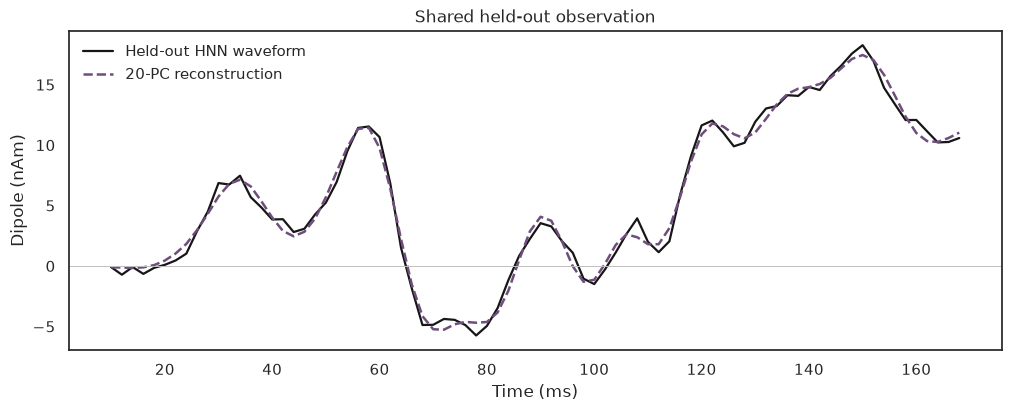

In [ ]:
fig, axis = plt.subplots(figsize=(10, 4), layout="constrained")

axis.plot(TIME_GRID, case["dipole"][0], color=OBSERVED_COLOR, linewidth=1.6, label="Held-out HNN waveform")
axis.plot(
    TIME_GRID, case_reconstruction, color=PCA_COLOR, linestyle="--", linewidth=1.8,
    label=f"{N_PCA_COMPONENTS}-PC reconstruction"
)
axis.axhline(0.0, color="0.75", linewidth=0.7)
axis.set(title="Shared held-out observation", xlabel="Time (ms)", ylabel="Dipole (nAm)")
axis.legend(frameon=False)

## 4. Neural posterior estimation

NPE learns $q_\phi(\theta\mid z)$, where $z$ represents the 20 PC scores. Every physical parameter is strictly positive, so the adapter takes its logarithm, concatenates all seven values, and hands the scores to the flow as conditions. The inverse transform guarantees positivity but imposes no upper limit. A similiar effect can be achieved by using a `constrain(lower=0)` transform.

In [6]:
npe_adapter = (
    bf.Adapter()
    .log(PARAMETER_NAMES)
    .concatenate(PARAMETER_NAMES, into="inference_variables")
    .rename("dipole_pca", "inference_conditions")
)

npe_network = bf.networks.CouplingFlow(
    depth=2, 
    transform="spline", 
    subnet_kwargs={
        "widths": (64, 64), 
        "dropout": NPE_DROPOUT
    }
)

npe_workflow = bf.BasicWorkflow(
    adapter=npe_adapter, 
    inference_network=npe_network, 
    standardize="all", 
    initial_learning_rate=1e-3
)

npe_history = npe_workflow.fit_offline(train, validation_data=validation, epochs=1000, batch_size=512, verbose=0)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.


INFO:bayesflow:Building on a test batch.


INFO:bayesflow:Training completed in 1.83 minutes.


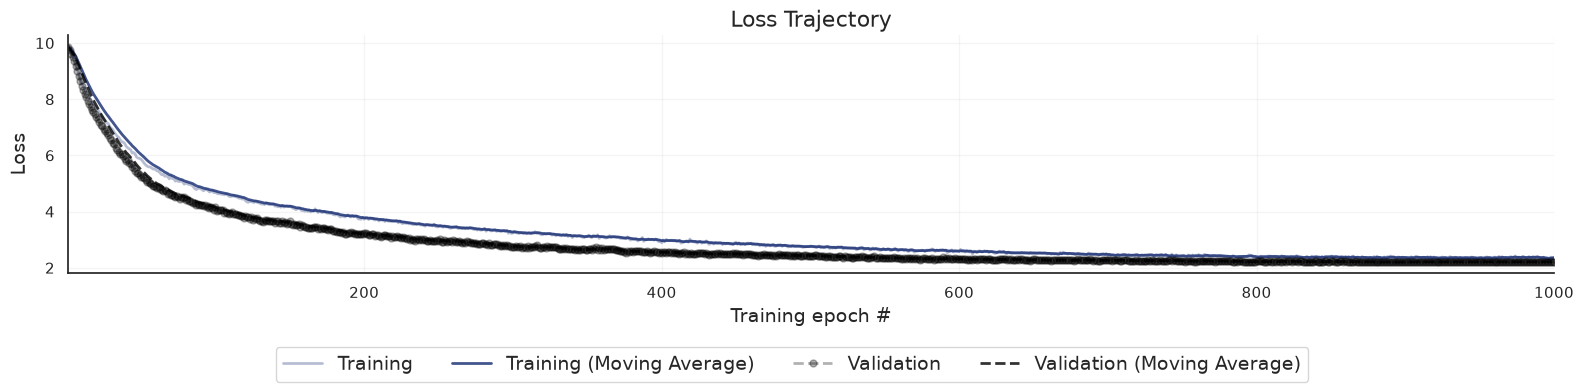

In [ ]:
fig = bf.diagnostics.loss(npe_history)

Recovery on the full held-out test set checks whether posterior centers track the known generating values. The intervals also expose mechanisms that remain weakly identified under this fast budget.


In [8]:
npe_test_posterior = npe_workflow.sample(conditions={"dipole_pca": test["dipole_pca"]}, num_samples=500)

INFO:bayesflow:Sampling completed in 4.53 seconds.


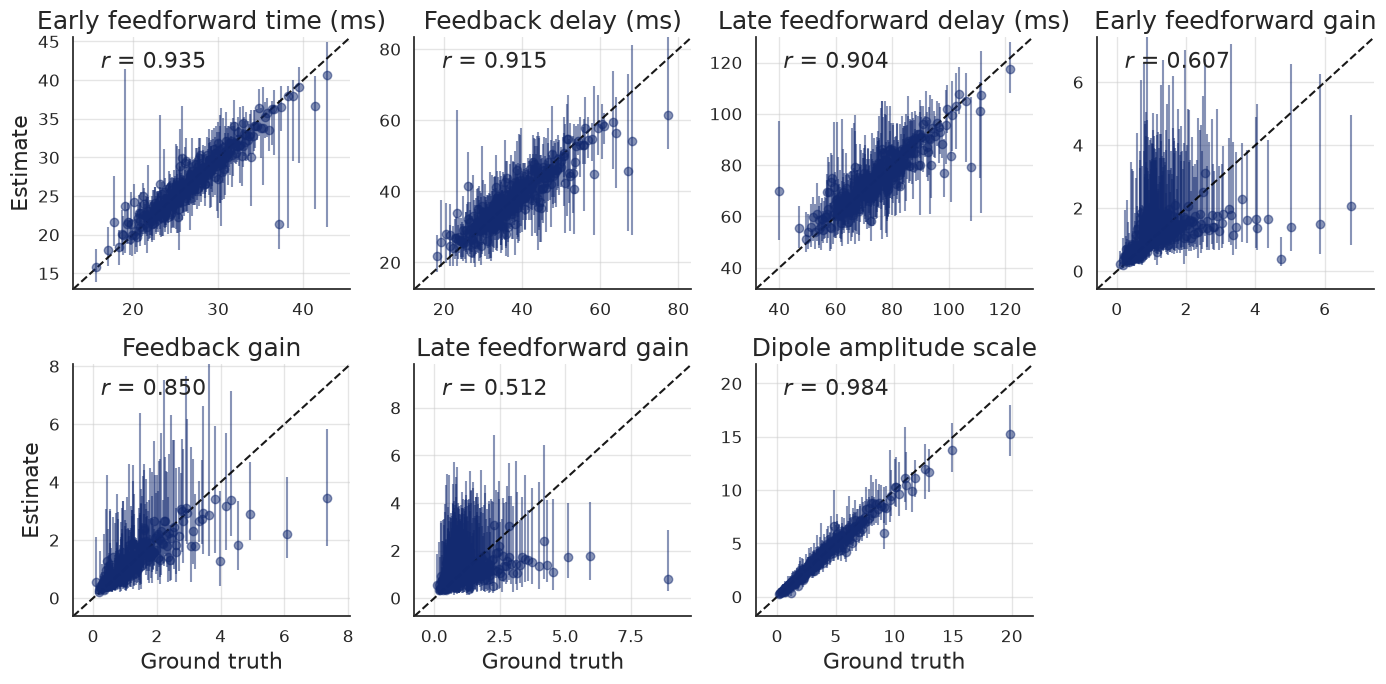

In [ ]:
fig = bf.diagnostics.recovery(
    npe_test_posterior,
    test,
    variable_keys=PARAMETER_NAMES,
    variable_names=PARAMETER_LABELS,
    figsize=(14, 7),
    num_col=4,
    num_row=2,
)

>Note: We will not perform these checks for NLE due to its lack of amortization. We would have to run MCMC for each point in the plot, which we want to avoid in this tutorial. You are encouraged to perform further amortized checks, such as simulation-based calibration (SBC).

In [10]:
npe_case_posterior = npe_workflow.sample(conditions={"dipole_pca": case["dipole_pca"]}, num_samples=2000)

INFO:bayesflow:Sampling completed in 3.27 seconds.


## 5. Neural likelihood estimation

NLE reverses the learning direction and estimates $q_\psi(z\mid\theta)$. The same PC scores are now inference variables and the same seven log-parameters are conditions. Downstream posterior inference still requires Monte Carlo sampling. We use thsi as an opportunity to demonstarte our PyMC wrapper.

In [11]:
nle_adapter = (
    bf.Adapter()
    .log(PARAMETER_NAMES)
    .concatenate(PARAMETER_NAMES, into="inference_conditions")
    .rename("dipole_pca", "inference_variables")
)

nle_network = bf.networks.CouplingFlow(
    depth=2, 
    transform="spline", 
    subnet_kwargs={
        "widths": (128, 128), 
        "dropout": NLE_DROPOUT
    }
)

nle_workflow = bf.BasicWorkflow(
    adapter=nle_adapter, 
    inference_network=nle_network, 
    standardize="all", 
    initial_learning_rate=5e-4
)

nle_history = nle_workflow.fit_offline(train, validation_data=validation, epochs=500, batch_size=128, verbose=0)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.


INFO:bayesflow:Building on a test batch.


INFO:bayesflow:Training completed in 3.49 minutes.


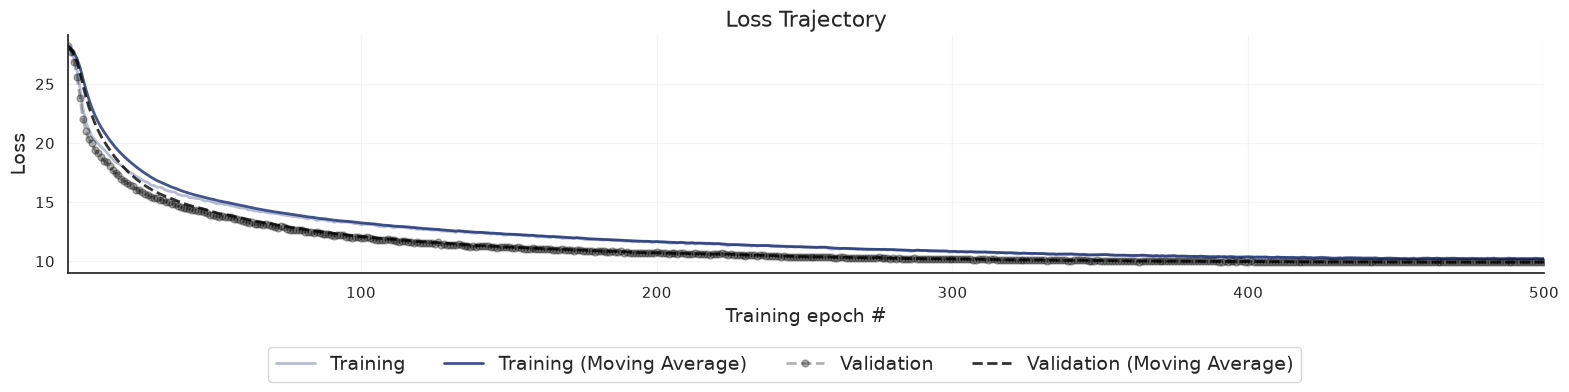

In [12]:
fig = bf.diagnostics.loss(nle_history)

The estimator saw all seven parameters in log coordinates. PyMC samples the six log-normal circuit parameters and the Gamma amplitude scale directly in physical coordinates, then logs them only at the neural-likelihood boundary.

`NeuralDistribution` calls the trained estimator directly. Its parameter order must exactly match the adapted condition vector, and the complete PC vector is one non-exchangeable observation.


In [13]:
log_names = [f"log_{name}" for name in PARAMETER_NAMES]

neural_likelihood = NeuralDistribution(
    estimator=nle_workflow.estimator, 
    param_names=log_names, 
    exchangeable=False
)

def sample_nle_posterior(observed_pca, *, draws=1000, tune=1000, chains=4, sampler="nuts"):
    "We will reuse this function for both simulated and real data."

    def make_prior(name):
        spec = PRIOR_SPECS[name]
        if spec["family"] == "lognormal":
            return pm.LogNormal(name, mu=log(spec["median"]), sigma=spec["log_sd"])
        return pm.Gamma(name, alpha=spec["shape"], beta=1.0 / spec["scale"])

    with pm.Model():
        parameters = {name: make_prior(name) for name in PARAMETER_NAMES}

        pm.Deterministic("feedback_time", parameters["early_feedforward_time"] + parameters["feedback_delay"])
        pm.Deterministic(
            "late_feedforward_time",
            parameters["early_feedforward_time"]
            + parameters["feedback_delay"]
            + parameters["late_feedforward_delay"],
        )

        likelihood_parameters = {f"log_{name}": pm.math.log(value) for name, value in parameters.items()}
        neural_likelihood("dipole_pca", observed=observed_pca.ravel(), **likelihood_parameters)

        if sampler == "smc":
            return pm.sample_smc(draws=draws, chains=chains, cores=1, progressbar=False)
        return pm.sample(draws=draws, tune=tune, chains=chains, cores=1, target_accept=0.9, progressbar=False)


nle_trace = sample_nle_posterior(case["dipole_pca"])

Initializing NUTS using jitter+adapt_diag...


INFO:pymc.sampling.mcmc:Initializing NUTS using jitter+adapt_diag...


/home/radevs/Desktop/Projects/bayesflow/.venv/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(


Sequential sampling (4 chains in 1 job)


INFO:pymc.sampling.mcmc:Sequential sampling (4 chains in 1 job)


NUTS: [early_feedforward_time, feedback_delay, late_feedforward_delay, early_feedforward_gain, feedback_gain, late_feedforward_gain, observation_gain]


INFO:pymc.sampling.mcmc:NUTS: [early_feedforward_time, feedback_delay, late_feedforward_delay, early_feedforward_gain, feedback_gain, late_feedforward_gain, observation_gain]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 77 seconds.


INFO:pymc.sampling.mcmc:Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 77 seconds.


In [14]:
az.summary(nle_trace, var_names=PARAMETER_NAMES, hdi_prob=0.9, round_to=3)

,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
early_feedforward_time,31.604,2.316,27.677,35.424,0.051,0.044,2110.670,1852.018,1.001
feedback_delay,40.370,3.388,34.604,45.756,0.082,0.066,1714.488,2110.832,1.000
late_feedforward_delay,71.390,5.928,62.133,80.989,0.136,0.123,1891.940,2333.003,1.000
early_feedforward_gain,0.792,0.286,0.443,1.128,0.007,0.026,2091.718,1623.186,1.001
feedback_gain,1.296,0.494,0.596,2.004,0.012,0.014,1766.125,1948.524,1.001
late_feedforward_gain,0.560,0.324,0.147,0.976,0.007,0.019,2021.006,2512.235,1.001
observation_gain,2.623,0.313,2.139,3.142,0.007,0.006,2124.050,2414.605,1.001


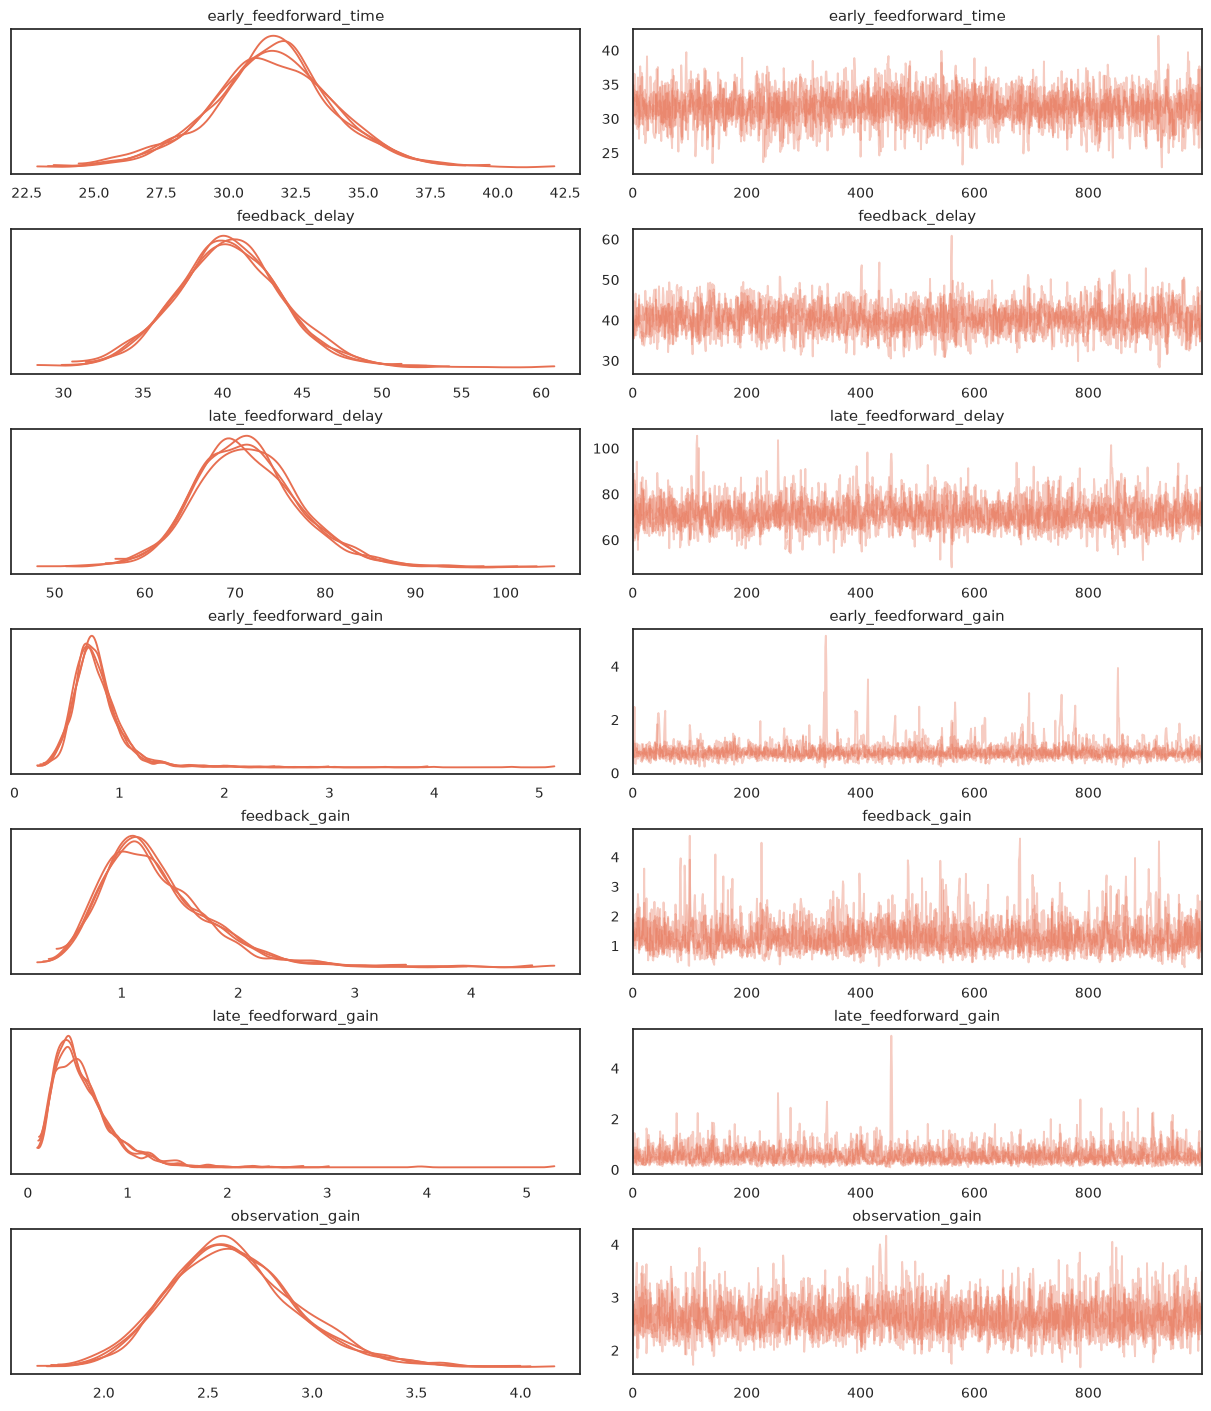

In [15]:
axes = az.plot_trace(
    nle_trace,
    var_names=PARAMETER_NAMES,
    figsize=(12, 14),
    chain_prop={"color": [METHOD_COLORS["NLE"]]},
    backend_kwargs={"layout": "constrained"},
)

## 6. Posterior comparison on a held-out HNN waveform

Both methods saw the same training simulations, PCA transform, held-out observation, and used the same priors. We can now compare the resulting posteriors.

In [ ]:
def flatten_npe_posterior(posterior):
    return {name: posterior[name].reshape(-1) for name in PARAMETER_NAMES}


def flatten_nle_posterior(trace):
    return {name: trace.posterior[name].values.ravel() for name in PARAMETER_NAMES}


def plot_posterior_comparison(npe_draws, nle_draws, prior_draws, *, truth=None, title):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), layout="constrained")

    for axis, name, label in zip(axes.flat, PARAMETER_NAMES, PARAMETER_LABELS):
        prior_values = prior_draws[name].ravel()
        displayed = np.concatenate([prior_values, npe_draws[name], nle_draws[name]])
        if truth is not None:
            displayed = np.append(displayed, truth[name])

        lower, upper = np.quantile(displayed, [0.0025, 0.9975])
        if truth is not None:
            lower = min(lower, truth[name])
            upper = max(upper, truth[name])
        padding = 0.04 * (upper - lower)
        bin_edges = np.linspace(max(0, lower - padding), upper + padding, 31)

        axis.hist(prior_values, bins=bin_edges, density=True, color=PRIOR_COLOR, alpha=0.18, label="Prior")

        prior_lower, prior_upper = np.quantile(prior_values, [0.05, 0.95])
        prior_width = prior_upper - prior_lower
        for method, draws in (("NPE", npe_draws[name]), ("NLE", nle_draws[name])):
            color = METHOD_COLORS[method]
            if np.std(draws) < 0.01 * prior_width:
                axis.axvline(np.median(draws), color=color, linewidth=2, label=method)
            else:
                axis.hist(draws, bins=bin_edges, density=True, histtype="step", color=color, linewidth=2, label=method)

        if truth is not None:
            axis.axvline(truth[name], color=OBSERVED_COLOR, linestyle="--", linewidth=1.5, label="Truth")

        axis.set(title=label, xlim=(bin_edges[0], bin_edges[-1]), ylabel=None)
        axis.set_yticks([])

    for axis in axes.flat[len(PARAMETER_NAMES) :]:
        axis.remove()

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=len(labels), frameon=False)
    fig.suptitle(title)
    return fig

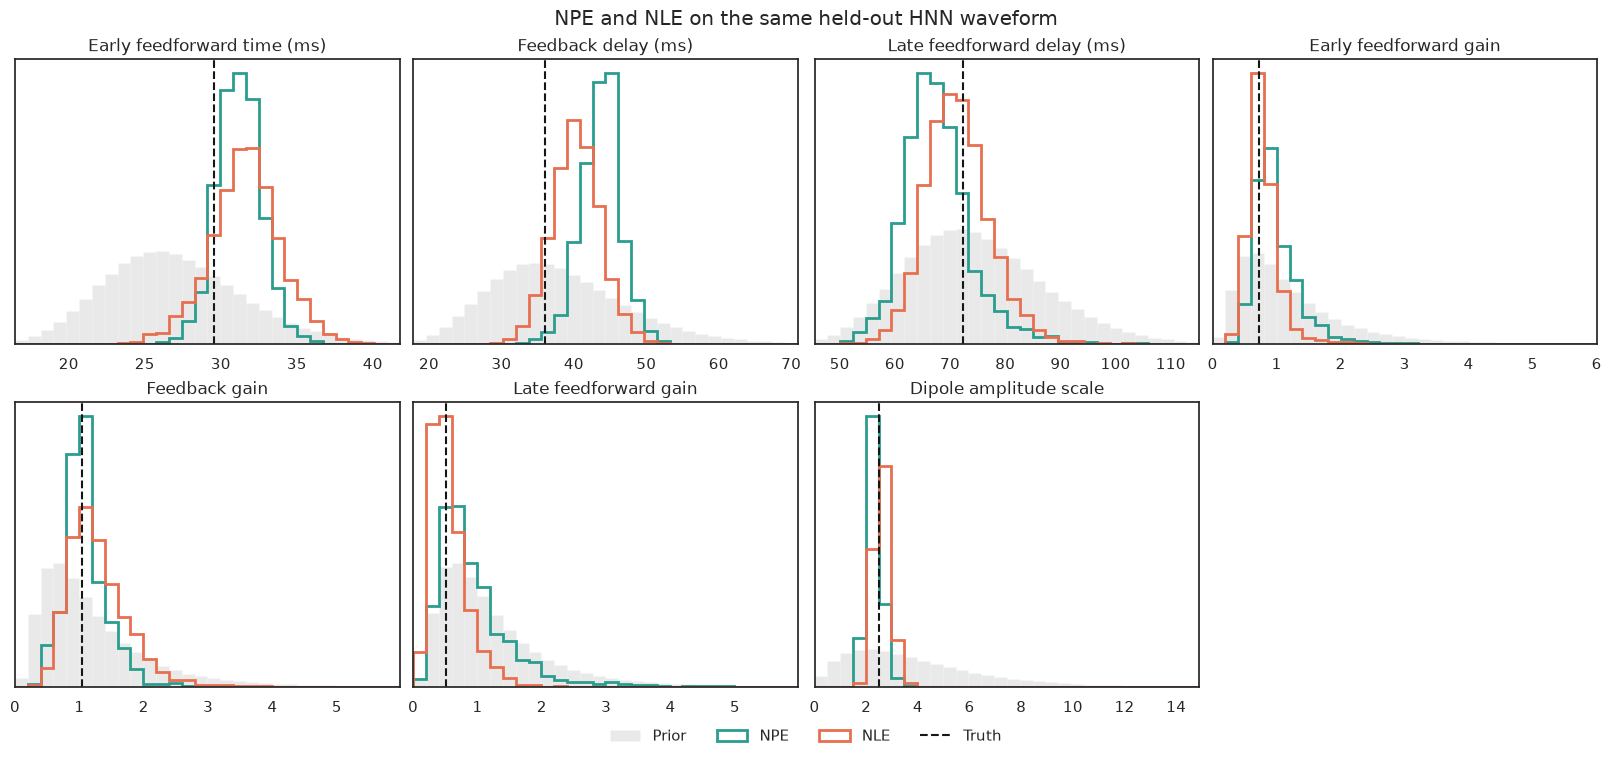

In [ ]:
npe_draws = flatten_npe_posterior(npe_case_posterior)
nle_draws = flatten_nle_posterior(nle_trace)

fig = plot_posterior_comparison(
    npe_draws,
    nle_draws,
    train,
    truth=case_truth,
    title="NPE and NLE on the same held-out HNN waveform",
)

NPE and NLE agree on the held-out simulated case.

In [18]:
comparison_rows = []
for name, label in zip(PARAMETER_NAMES, PARAMETER_LABELS):
    row = {"parameter": label, "truth": case_truth[name]}

    for method, draws in (("NPE", npe_draws[name]), ("NLE", nle_draws[name])):
        lower, median, upper = np.quantile(draws, [0.05, 0.5, 0.95])
        row[f"{method} median"] = median
        row[f"{method} 90% interval"] = f"[{lower:.3f}, {upper:.3f}]"

    comparison_rows.append(row)

pd.DataFrame(comparison_rows)

,parameter,truth,NPE median,NPE 90% interval,NLE median,NLE 90% interval
0,Early feedforward time (ms),29.524998,31.154045,"[28.803, 33.595]",31.629365,"[27.627, 35.399]"
1,Feedback delay (ms),36.031094,43.841114,"[39.164, 48.143]",40.317148,"[34.817, 46.003]"
2,Late feedforward delay (ms),72.354980,66.982861,"[58.980, 78.459]",71.017059,"[62.567, 81.583]"
3,Early feedforward gain,0.720585,0.896855,"[0.580, 1.738]",0.746347,"[0.482, 1.207]"
4,Feedback gain,1.036660,1.037143,"[0.583, 1.719]",1.203253,"[0.680, 2.163]"
5,Late feedforward gain,0.509323,0.783807,"[0.317, 2.048]",0.487017,"[0.208, 1.157]"
6,Dipole amplitude scale,2.495499,2.252333,"[1.873, 2.833]",2.596954,"[2.164, 3.173]"


## 7. Posterior predictive checks on the held-out HNN waveform

We can now use the samples from each posterior and run a new stochastic HNN simulation for every draw to check whether posterior uncertainty properly propagates into predictive uncertainty. HNN makes it very easy to generate a batch of new simulations using the `simulate_parameter_batch` function.

In [19]:
def subset_draws(draws, n_draws):
    indices = np.random.choice(len(next(iter(draws.values()))), size=n_draws, replace=False)
    return {name: draws[name][indices, None] for name in PARAMETER_NAMES}


def plot_predictive_comparison(predictives, observed, *, observed_label, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True, sharey=True, layout="constrained")

    for axis, method in zip(axes, ("NPE", "NLE")):
        lower, median, upper = np.quantile(predictives[method], [0.05, 0.5, 0.95], axis=0)
        color = METHOD_COLORS[method]

        axis.fill_between(TIME_GRID, lower, upper, color=color, alpha=0.18, label="90% predictive interval")
        axis.plot(TIME_GRID, median, color=color, linewidth=2, label="Predictive median")
        axis.plot(TIME_GRID, observed, color=OBSERVED_COLOR, linewidth=1.2, label=observed_label)

        axis.set(title=method, xlabel="Time (ms)", ylabel="Dipole (nAm)")
        axis.legend(frameon=False)

    fig.suptitle(title)
    return fig

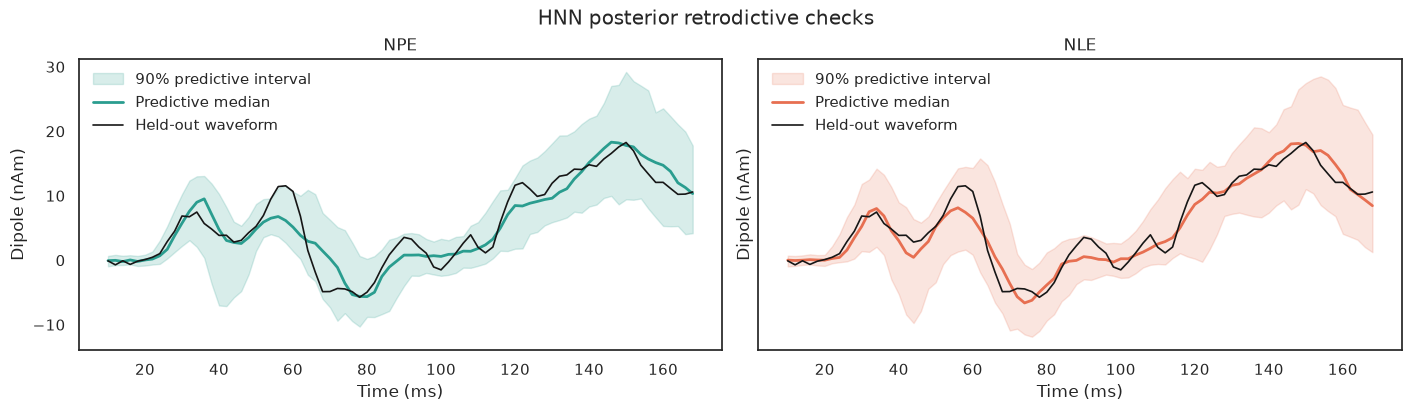

In [20]:
held_out_parameters = {
    "NPE": subset_draws(npe_draws, N_POSTERIOR_PREDICTIVE),
    "NLE": subset_draws(nle_draws, N_POSTERIOR_PREDICTIVE),
}

held_out_predictives = {
    method: hnn.simulate_parameter_batch(parameters, n_jobs=N_JOBS)
    for method, parameters in held_out_parameters.items()
}

fig = plot_predictive_comparison(
    held_out_predictives,
    case["dipole"][0],
    observed_label="Held-out waveform",
    title="HNN posterior retrodictive checks",
)

## 8. Analyzing real tactile MEG data

HNN publishes a [source-localized S1 dipole](https://github.com/jonescompneurolab/hnn-data/blob/main/MEG_detection_data/yes_trial_S1_ERP_all_avg.txt) from a tactile-detection experiment. We will now perform inference on that data, compare posteriors, and perform posterior retrodictive checks.

Real data that are highly unlikely under the prior predictive may result in biased posterior approximations. Amortized Bayesian inference is trained on the model-implied distribution $p(x)=\mathbb{E}_{p(\theta)}[p(x\mid\theta)]$, so observations $x_{\mathrm{obs}}$ outside its typical set force the network to extrapolate. The potential **extrapolation bias** can make $q(\theta\mid x_{\mathrm{obs}})$ unreliable even when inference is accurate for typical simulations. Comparing observed summaries $\phi(x_{\mathrm{obs}})$ with the prior-predictive distribution of $\phi(x)$ is therefore a useful diagnostic.

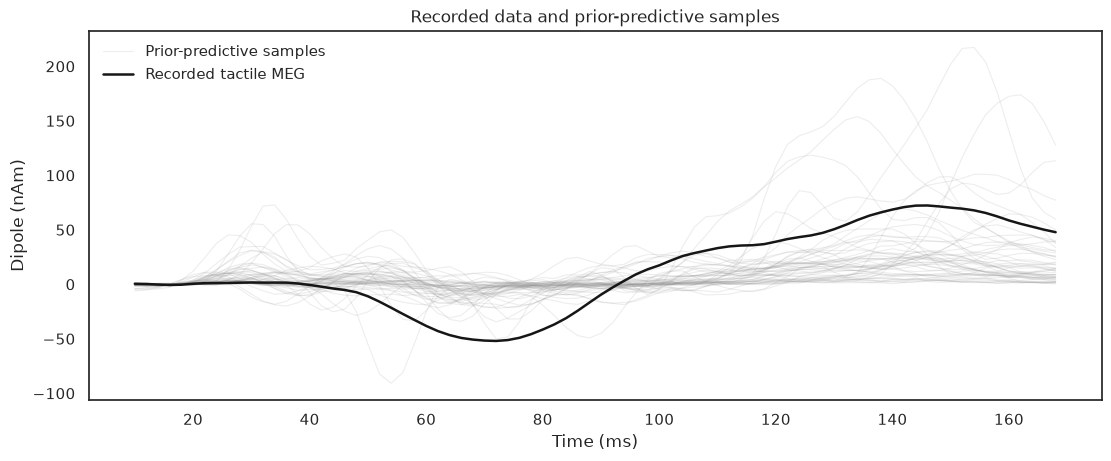

In [21]:
experimental_waveform = hnn.load_experimental_waveform()
experimental_pca = pca.transform(experimental_waveform[None, :])

fig, axis = plt.subplots(figsize=(11, 4.5), layout="constrained")
for index, waveform in enumerate(train["dipole"][show_indices]):
    axis.plot(
        TIME_GRID, waveform, color=PRIOR_COLOR, alpha=0.15, linewidth=0.8,
        label="Prior-predictive samples" if index == 0 else None,
    )

axis.plot(TIME_GRID, experimental_waveform, color=OBSERVED_COLOR, linewidth=1.8, label="Recorded tactile MEG")
axis.set(title="Recorded data and prior-predictive samples", xlabel="Time (ms)", ylabel="Dipole (nAm)")
axis.legend(frameon=False)

NPE is amortized and just needs a batch of forward passes:

In [22]:
experimental_npe_raw = npe_workflow.sample(conditions={"dipole_pca": experimental_pca}, num_samples=2000)

INFO:bayesflow:Sampling completed in 0.02 seconds.


NLE, on the other hand, needs ot invoke MCMC:

In [23]:
experimental_nle_trace = sample_nle_posterior(experimental_pca)

Initializing NUTS using jitter+adapt_diag...


INFO:pymc.sampling.mcmc:Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


INFO:pymc.sampling.mcmc:Sequential sampling (4 chains in 1 job)


NUTS: [early_feedforward_time, feedback_delay, late_feedforward_delay, early_feedforward_gain, feedback_gain, late_feedforward_gain, observation_gain]


INFO:pymc.sampling.mcmc:NUTS: [early_feedforward_time, feedback_delay, late_feedforward_delay, early_feedforward_gain, feedback_gain, late_feedforward_gain, observation_gain]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 191 seconds.


INFO:pymc.sampling.mcmc:Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 191 seconds.


Which also means we have access to all the canonical MCMC diagnostics:

In [24]:
az.summary(experimental_nle_trace, var_names=PARAMETER_NAMES, hdi_prob=0.9, round_to=3)

,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
early_feedforward_time,29.146,4.259,22.537,37.102,0.237,0.245,499.836,248.568,1.004
feedback_delay,39.735,4.975,31.533,47.536,0.178,0.105,803.462,1580.531,1.001
late_feedforward_delay,77.638,11.165,61.219,94.339,0.413,0.484,871.189,785.403,1.008
early_feedforward_gain,0.533,0.618,0.111,0.807,0.031,0.113,495.773,233.917,1.008
feedback_gain,0.962,0.457,0.354,1.549,0.013,0.017,1230.428,1540.281,1.001
late_feedforward_gain,1.328,0.916,0.247,2.470,0.024,0.040,1719.494,1827.450,1.003
observation_gain,11.919,1.774,9.261,14.762,0.061,0.040,832.671,1399.414,1.000


In [25]:
experimental_npe = flatten_npe_posterior(experimental_npe_raw)
experimental_nle = flatten_nle_posterior(experimental_nle_trace)

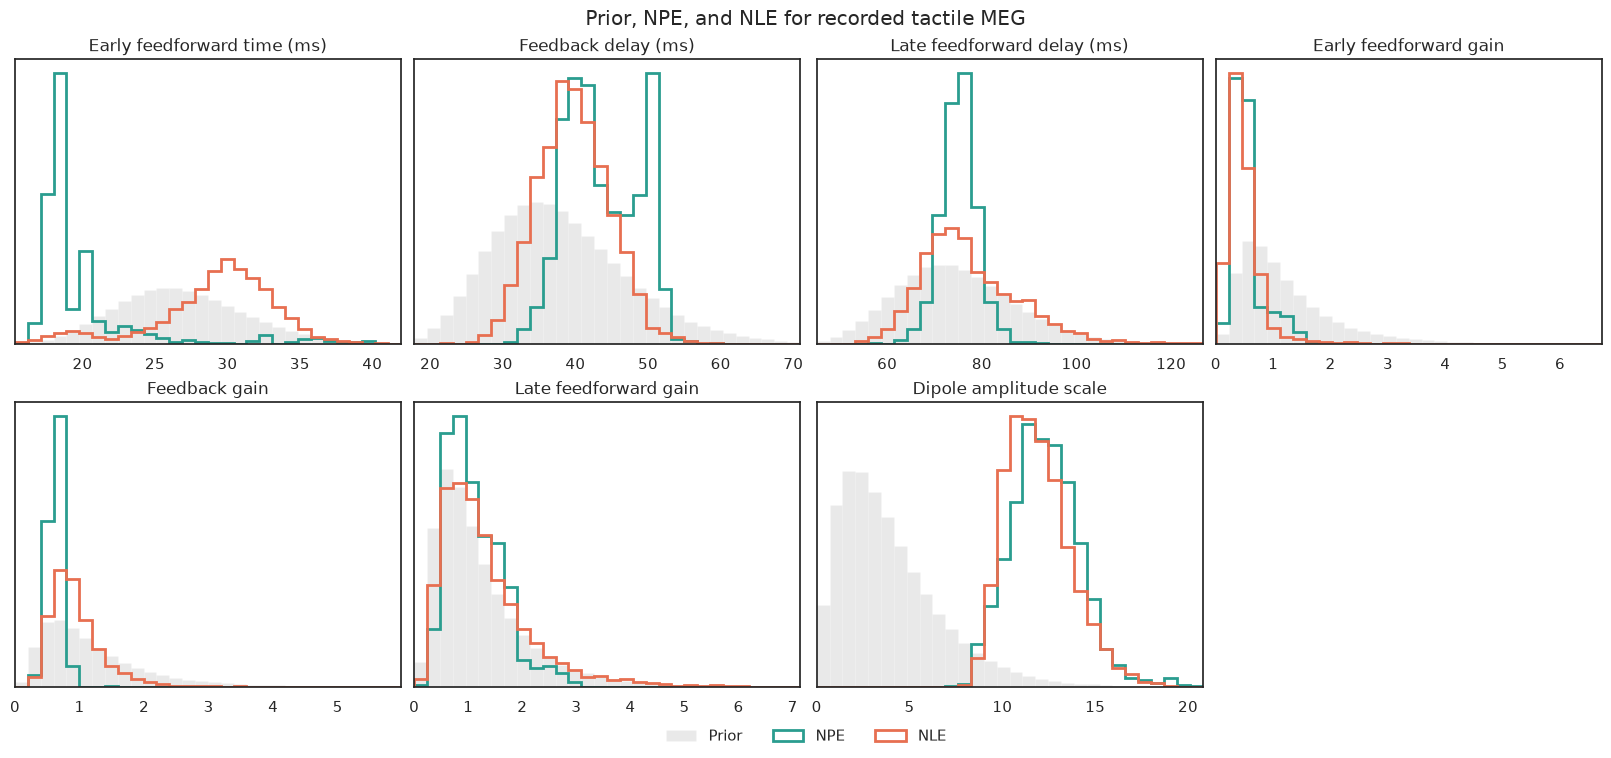

In [26]:
fig = plot_posterior_comparison(
    experimental_npe,
    experimental_nle,
    train,
    title="Prior, NPE, and NLE for recorded tactile MEG",
)

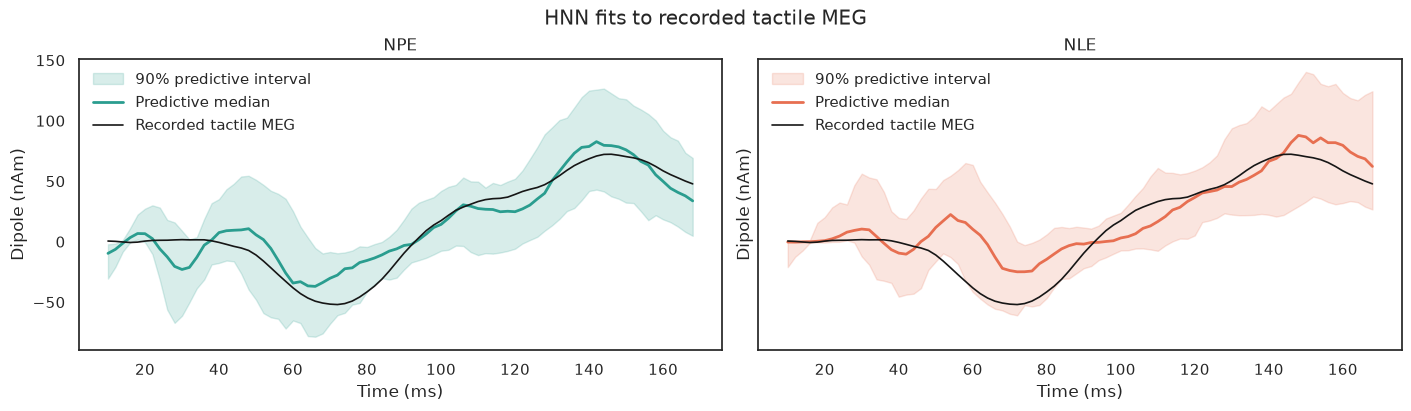

In [27]:
experimental_parameters = {
    "NPE": subset_draws(experimental_npe, N_POSTERIOR_PREDICTIVE),
    "NLE": subset_draws(experimental_nle, N_POSTERIOR_PREDICTIVE),
}

experimental_predictives = {
    method: hnn.simulate_parameter_batch(parameters, n_jobs=N_JOBS)
    for method, parameters in experimental_parameters.items()
}

fig = plot_predictive_comparison(
    experimental_predictives,
    experimental_waveform,
    observed_label="Recorded tactile MEG",
    title="HNN fits to recorded tactile MEG",
)

## 9. Further steps

Explore `EnsembleWorkflow` with different inference networks to assess how the network architecture affects the posterior. You can also replace PCA with a trainable summary network so that waveform features are learned jointly with inference.
